# 02 - Le panel « maire sortant x élection »

Avant de mesurer l'effet d'une procédure judiciaire, il faut savoir comment les
électeurs traitent **un maire sortant ordinaire** : se représente-t-il ? sa liste
gagne-t-elle ? son score progresse-t-il ? Ce notebook construit ce point de
référence à partir de `src/panel.py`, qui rapproche :

- les maires sortants (liste officielle 2026 ; pour 2020, tête de la liste gagnante en 2014) ;
- les candidatures et résultats par liste des municipales 2014, 2020 et 2026 ;
- le RNE (maires en fonction en août 2026) et le COG (fusions de communes).

Une ligne = une commune x une élection (2020 ou 2026). Champ : communes au scrutin
de liste, hors Paris, Lyon, Marseille. Les communes dont le périmètre a changé
entre deux scrutins (fusions) sont écartées des analyses.

Prérequis : `python scripts/download_data.py`. Les fichiers intermédiaires sont
régénérés à la volée.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # notebook lancé depuis notebooks/
sys.path.insert(0, str(ROOT / "src"))
import panel as P  # noqa: E402

pd.set_option("display.width", 200)

# Charte graphique : deux séries au plus (2020, 2026), axes discrets.
COULEURS = {2020: "#2a78d6", 2026: "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Construction et contrôle des appariements

In [2]:
panel_brut = P.build_panel()
display(P.resume(panel_brut))

,communes,sortant_candidat,sortant_tete_liste,liste_gagnante_si_candidat,tete_liste_prec,delta_pct_disponible,perimetre_modifie
annee,,,,,,,
2020,9470,0.666,0.89,0.837,1.0,0.666,0.043
2026,34768,0.735,0.869,0.905,0.25,0.190,0.003


Lecture : en 2026, 73 % des maires sortants figurent sur une liste au 1er tour, et
87 % de ceux-là la conduisent. Le score de l'élection précédente n'est connu que
pour une minorité de communes en 2026 : avant 2026, les communes de moins de
1000 habitants votaient au scrutin plurinominal, sans score de liste.

Le rapprochement des noms se fait par étapes de plus en plus souples (nom et
prénom exacts, puis noms composés, puis fautes de frappe). La quasi-totalité des
appariements est exacte :

In [3]:
display(panel_brut.groupby("annee").methode_appariement.value_counts(dropna=False).unstack(0))

annee,2020,2026
methode_appariement,,
nom1_prenom1,34,131
nom_partiel_prenom1,18,103
nom_prenom,6195,25010
nom_prenom1,47,277
similarite,12,40
<NA>,3164,9207


Contrôle externe en 2026 : le RNE d'août 2026 dit qui est effectivement maire
après l'élection. Si nos appariements sont bons, un sortant « non candidat » ne
devrait presque jamais être réélu maire, et un sortant dont la liste a perdu non
plus.

In [4]:
p26 = panel_brut[panel_brut.annee == 2026]
display(pd.crosstab(p26.liste_sortant_gagnante.astype("string").fillna("non candidat"),
                    p26.reelu_maire, margins=True))

reelu_maire,False,True,All
liste_sortant_gagnante,,,
False,2423,3,2426
True,1585,21547,23132
non candidat,9126,84,9210
All,13134,21634,34768


Les deux cases « impossibles » (liste perdante ou non candidat, mais maire en août)
comptent moins d'une centaine de communes sur près de 35 000 : changements de nom
complets (mariage) et homonymies résiduelles. À l'inverse, environ 1 600 sortants
élus sur la liste gagnante ne sont pas redevenus maires : ce n'est pas une erreur,
le conseil municipal a élu quelqu'un d'autre (souvent quand le sortant n'était pas
tête de liste).

In [5]:
TAILLES = [0, 500, 1000, 3500, 10_000, 30_000, np.inf]
LIBELLES = ["< 500", "500-1 000", "1 000-3 500", "3 500-10 000", "10 000-30 000", "30 000 +"]

panel = panel_brut[~panel_brut.perimetre_modifie].copy()
panel["taille"] = pd.cut(panel.inscrits, TAILLES, labels=LIBELLES, right=False)
panel["dispute"] = panel.n_listes > 1  # au moins deux listes au 1er tour
print(f"{len(panel_brut) - len(panel)} communes écartées (périmètre modifié par une fusion)")

509 communes écartées (périmètre modifié par une fusion)


## 2. Le sortant se représente-t-il, et gagne-t-il ?

Taille de commune mesurée par le nombre d'**inscrits** au 1er tour. Le taux de
victoire est calculé sur les seules communes **disputées** (au moins deux listes) :
avec une liste unique, la victoire est acquise et ne dit rien du jugement des électeurs.
En 2020, la tranche « < 500 inscrits » est vide : le panel 2020 ne couvre que les
communes au scrutin de liste en 2014 (≥ 1000 habitants).

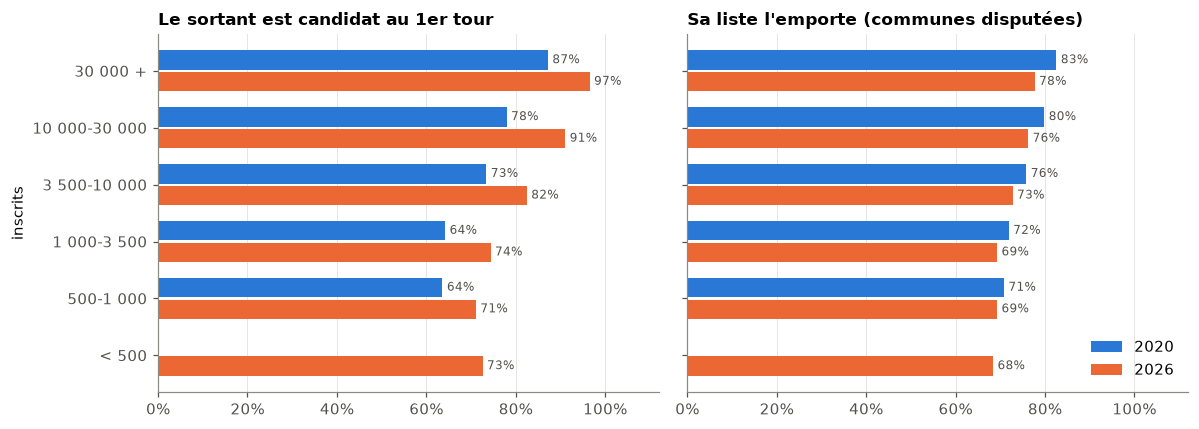

,candidat,victoire_si_dispute,n_disputes
annee,,,
2020,0.668,0.74,3802
2026,0.735,0.701,8081


In [6]:
def taux_par_taille(df: pd.DataFrame, variable: str) -> pd.DataFrame:
    """Taux moyen de `variable` par tranche de taille et par année (tranches de moins de 30 communes masquées)."""
    g = df.groupby(["taille", "annee"], observed=True)[variable].agg(["mean", "count"])
    return g["mean"].where(g["count"] >= 30).unstack("annee")


def barres_groupees(ax, tableau: pd.DataFrame, titre: str) -> None:
    """Barres horizontales groupées, une série par année, valeurs écrites au bout des barres."""
    y = np.arange(len(tableau))
    h = 0.38
    for i, annee in enumerate(tableau.columns):
        v = tableau[annee].to_numpy(dtype=float)
        pos = y + (0.5 - i) * h  # axe inversé : la première année en haut
        ax.barh(pos, v, height=h - 0.04, color=COULEURS[annee], label=str(annee))
        for yy, vv in zip(pos, v):
            if not np.isnan(vv):
                ax.text(vv + 0.01, yy, f"{vv:.0%}", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y, tableau.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(titre, loc="left")


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
barres_groupees(axes[0], taux_par_taille(panel, "sortant_candidat"), "Le sortant est candidat au 1er tour")
candidats_disputes = panel[panel.sortant_candidat & panel.dispute]
barres_groupees(axes[1], taux_par_taille(candidats_disputes, "liste_sortant_gagnante"),
                "Sa liste l'emporte (communes disputées)")
axes[0].set_ylabel("inscrits")
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

display(panel.groupby("annee").agg(
    candidat=("sortant_candidat", "mean"),
).join(candidats_disputes.groupby("annee").agg(
    victoire_si_dispute=("liste_sortant_gagnante", "mean"), n_disputes=("code_insee", "size"))).round(3))

**Lecture.**
- Plus la commune est grande, plus le maire sortant se représente : moins de trois
  sur quatre dans les petites communes, plus de neuf sur dix au-delà de 10 000
  inscrits en 2026. Dans les villages, l'arrêt après un ou deux mandats est fréquent.
- Quand il y a une vraie compétition, la liste du sortant gagne environ 7 fois sur
  10 (74 % en 2020, 70 % en 2026). Ce taux croît avec la taille : autour de 70 %
  sous 3 500 inscrits, autour de 80 % au-delà de 10 000. C'est l'**avantage du
  sortant** bien connu en science politique, plus marqué là où le maire est une
  figure installée et dispose d'une équipe et d'un bilan visibles.
- Le taux de victoire baisse légèrement entre 2020 et 2026 dans toutes les
  tranches : l'environnement de 2026 a été un peu moins favorable aux sortants.
- Conséquence pour la suite : un sortant visé par une procédure devra être comparé
  à des sortants **de même taille de commune et de même élection** ; un taux de
  défaite de 25 à 30 % n'est pas en soi une sanction, c'est la norme.

## 3. Évolution du score du sortant d'une élection à l'autre

On garde les sortants têtes de liste aux deux élections, dans des communes
disputées les deux fois : l'écart de score (en points de % des exprimés, au 1er
tour) mesure alors directement le gain ou la perte d'adhésion.

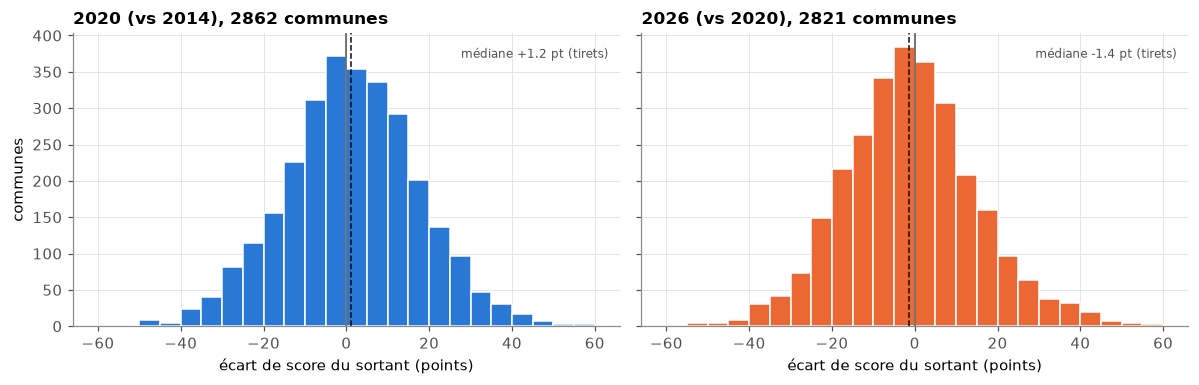

,count,mean,std,min,25%,50%,75%,max,part_en_baisse
annee,,,,,,,,,
2020,2862.0,1.4,16.1,-52.0,-9.0,1.2,11.9,62.4,0.468
2026,2821.0,-1.0,16.2,-55.1,-11.4,-1.4,8.4,59.5,0.538


In [7]:
evol = panel[panel.sortant_tete_liste.fillna(False) & panel.tete_liste_prec & panel.dispute
             & (panel.n_listes_prec > 1) & panel.delta_pct_voix_exp.notna()]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, sharex=True)
bornes = np.arange(-60, 65, 5)
for ax, (annee, g) in zip(axes, evol.groupby("annee")):
    ax.hist(g.delta_pct_voix_exp, bins=bornes, color=COULEURS[annee], edgecolor="white", linewidth=1)
    med = g.delta_pct_voix_exp.median()
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.axvline(med, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.text(0.98, 0.95, f"médiane {med:+.1f} pt (tirets)", transform=ax.transAxes, fontsize=8,
            ha="right", va="top", color="#52514e")
    ax.set_title(f"{annee} (vs {annee - 6}), {len(g)} communes", loc="left")
    ax.set_xlabel("écart de score du sortant (points)")
axes[0].set_ylabel("communes")
fig.tight_layout()
plt.show()

display(evol.groupby("annee").delta_pct_voix_exp.describe().round(1)
        .join(evol.groupby("annee").delta_pct_voix_exp.apply(lambda s: (s < 0).mean()).rename("part_en_baisse").round(3)))

**Lecture.** L'écart de score est centré près de zéro mais très dispersé : un quart
des sortants perdent plus de 9 à 11 points, un quart en gagnent plus de 8 à 12.
En 2026, un peu plus de la moitié des sortants reculent, contre moins de la moitié
en 2020. Cette dispersion est le « bruit de fond » contre lequel il faudra
détecter une éventuelle sanction judiciaire : un recul de 5 points, isolé, ne
prouve rien.

Le lien entre cet écart et l'issue du scrutin est très net :

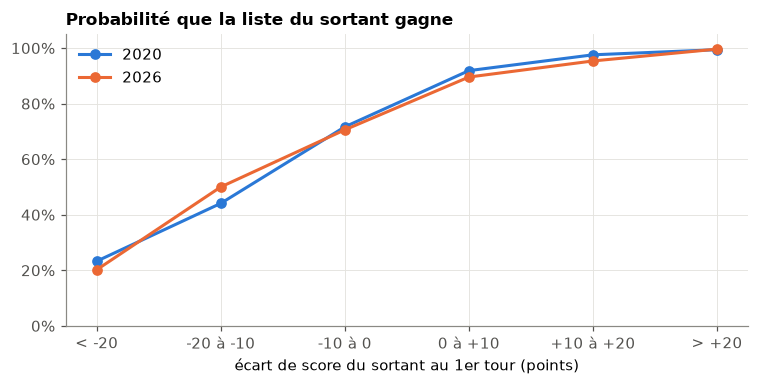

annee,2020,2026
classe_delta,,
< -20,0.233,0.202
-20 à -10,0.441,0.5
-10 à 0,0.716,0.706
0 à +10,0.919,0.896
+10 à +20,0.976,0.954
> +20,0.994,0.996


In [8]:
classes = [-100, -20, -10, 0, 10, 20, 100]
noms = ["< -20", "-20 à -10", "-10 à 0", "0 à +10", "+10 à +20", "> +20"]
evol = evol.assign(classe_delta=pd.cut(evol.delta_pct_voix_exp, classes, labels=noms))
victoire = evol.groupby(["classe_delta", "annee"], observed=True).liste_sortant_gagnante.mean().unstack("annee")

fig, ax = plt.subplots(figsize=(7, 3.6))
for annee in victoire.columns:
    ax.plot(victoire.index.astype(str), victoire[annee], marker="o", markersize=6, linewidth=2,
            color=COULEURS[annee], label=str(annee))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.05)
ax.set_xlabel("écart de score du sortant au 1er tour (points)")
ax.set_title("Probabilité que la liste du sortant gagne", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
display(victoire.round(3))

**Lecture.** Un sortant qui progresse gagne presque toujours (plus de 9 fois sur 10) ;
un recul de plus de 20 points le fait perdre près de 4 fois sur 5. Les deux
élections donnent des courbes quasi identiques : l'écart de score est une mesure
pertinente de la sanction électorale, qui se traduit effectivement en sièges.

## 4. Selon le bord politique

Les nuances ne sont attribuées par le ministère que dans les communes d'environ
3 500 habitants et plus ; les autres listes sont « non nuancées ». Le tableau
porte sur les sortants têtes de liste dans les communes disputées.

In [9]:
nuances = panel[panel.sortant_tete_liste.fillna(False) & panel.dispute & panel.bloc.notna()]
par_bloc = nuances.groupby(["bloc", "annee"]).agg(
    n=("code_insee", "size"),
    victoire=("liste_sortant_gagnante", "mean"),
    score_median=("pct_voix_exp", "median"),
    ecart_median=("delta_pct_voix_exp", "median"),
).round(3)
display(par_bloc.unstack("annee"))

n      victoire        score_median         ecart_median       
annee          2020 2026     2020   2026         2020    2026         2020   2026
bloc                                                                             
centre          235  356    0.715  0.775        51.77  55.400         0.37 -0.975
divers          131  234    0.733  0.705        53.90  53.585         3.80 -4.410
droite          771  822      0.8  0.783        54.82  56.250         1.84 -0.865
extreme_droite   11   15    0.818  0.867        53.47  60.790        21.43  9.820
gauche          501  644    0.804  0.694        55.20  51.060         1.83 -3.310

**Lecture.** Les taux de victoire des sortants de gauche, du centre, de droite et
divers sont proches (entre 70 et 80 %). Le seul écart notable est le recul des
sortants de gauche en 2026, dont le taux de victoire tombe sous celui de la
droite. Les sortants d'extrême droite sont trop peu nombreux (une quinzaine)
pour conclure. Il faudra donc, pour tester si la sanction judiciaire dépend du
parti, raisonner à l'intérieur d'un même bloc et d'une même élection.

## 5. Participation

La participation au 1er tour sert de variable de contrôle (et de résultat
possible : une affaire judiciaire peut démobiliser ou mobiliser).

In [10]:
display(panel.groupby("annee").agg(participation_mediane=("participation", "median"),
                                   participation_prec_mediane=("participation_prec", "median"),
                                   ecart_median=("delta_participation", "median")).round(3))

,participation_mediane,participation_prec_mediane,ecart_median
annee,,,
2020,0.457,0.671,-0.198
2026,0.632,0.457,0.122


**Lecture.** La participation s'effondre en 2020 (1er tour tenu au début de
l'épidémie de Covid-19, environ -20 points en médiane dans les communes du panel) puis
remonte en 2026. Toute comparaison 2020/2026 de la participation est donc
dominée par ce choc commun : l'effet d'une affaire judiciaire devra se lire
**par rapport aux autres communes de la même élection**, jamais en niveau absolu.

## Ce qu'il faut retenir

- Le panel couvre près de 35 000 communes en 2026 et 9 000 en 2020, avec des
  appariements de noms contrôlés par le RNE.
- Référence « sortant ordinaire » : il se représente 2 à 3 fois sur 4 (davantage
  dans les grandes communes) et sa liste gagne environ 7 fois sur 10 quand elle
  est concurrencée (8 sur 10 dans les grandes communes).
- L'écart de score d'une élection à l'autre est une mesure de sanction qui se
  traduit bien en victoires et défaites, mais son bruit de fond est large
  (écart-type d'environ 16 points).
- Pour la suite, les élus visés par une procédure seront rattachés au panel par
  `code_insee + nom_norm + prenom_norm`, et comparés aux sortants de même
  élection, taille de commune et bord politique.